# A1 - DNN using pytorch

This notebook uses the classic [MNIST handwritten digit](https://git-disl.github.io/GTDLBench/datasets/mnist_datasets/) dataset, which contains digit 0-9 images of size 28*28. Our goal is to build a dense neural network to predict the class of digit.

For standarization purposes, you are required to use pytorch.

In [1]:
###checking if we are getting GPU in colab
###if not, Runtime → Change runtime type and Set Hardware accelerator to GPU
!nvidia-smi

zsh:1: command not found: nvidia-smi


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

#device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')

# To work with cuda and macOS mps
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    elif torch.backends.mps.is_available():
        return torch.device('mps')
    else:
        return torch.device('cpu')

device = get_device()
print('Using device:', device)

# device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
# print(f"Using {device} device")
# torch.set_default_device(device)

Using device: mps


## The MNIST dataset - Preprocessing


### Get the data
MNIST dataset is provided by torch directly. The following codes show how to load it.



In [ ]:
help(datasets.MNIST)

In [3]:
# the data, shuffled and split between train and test sets
# (downloads automatically if not present)
train_ds = datasets.MNIST(root='./data', train=True, download=True)
test_ds  = datasets.MNIST(root='./data', train=False, download=True)

X_train_pre = train_ds.data.numpy()     # (N, 28, 28), uint8
y_train_pre = train_ds.targets.numpy()  # (N,), int64
X_test_pre  = test_ds.data.numpy()
y_test_pre  = test_ds.targets.numpy()

### Reshape and normalize the features

In [9]:
input_dim = 784 # 28*28
X_train = X_train_pre.reshape(X_train_pre.shape[0], input_dim)
X_test = X_test_pre.reshape(X_test_pre.shape[0], input_dim)
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')
X_train /= 255.
X_test /= 255.

print('training data shape:', X_train.shape)
print('{} train samples, {} test samples'.format(X_train.shape[0], X_test.shape[0]))

training data shape: (60000, 784)
60000 train samples, 10000 test samples


### convert class vectors to binary class matrices
convert class label to one-hot coding

In [10]:
y_train_pre[:5]

array([5, 0, 4, 1, 9])

In [11]:
num_classes = 10 # 0-9
# keep one-hot labels (to match the original notebook flow)
y_train = np.eye(num_classes, dtype=np.float32)[y_train_pre]
y_test = np.eye(num_classes, dtype=np.float32)[y_test_pre]

# the first 5 samples are 5,0,4,1,9
y_train[:5,]

array([[0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1.]], dtype=float32)

In [12]:
validation_split = 0.166667
index = np.random.permutation(X_train.shape[0])

train_idx = int(X_train.shape[0]*validation_split)

X_val, X_train = X_train[index[:train_idx]], X_train[index[train_idx:]]
y_val, y_train = y_train[index[:train_idx]], y_train[index[train_idx:]]

print('training data shape:', X_train.shape)
print('{} train samples, {} validation samples, {} test samples'\
      .format(X_train.shape[0], X_val.shape[0], X_test.shape[0]))

training data shape: (50000, 784)
50000 train samples, 10000 validation samples, 10000 test samples


## The models

### Build the model **1**

model 1: Build a 784-input 10-output perceptron, with no hidden layer for multi-class classification. This model is also known as the [multinomial logistic regression model](https://en.wikipedia.org/wiki/Multinomial_logistic_regression).

In [325]:
### Helper functions

class History:
    def __init__(self):
        self.history = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}
        self.epoch = []


def model_summary(model: nn.Module, input_dim: int = 784):
    """Simple summary: architecture + parameter counts."""
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(model)
    print(f"\nTotal params: {total:,}")
    print(f"Trainable params: {trainable:,}")



def make_loaders(X_train, y_train_idx, X_val, y_val_idx, batch_size=128):
    Xtr = torch.from_numpy(X_train).float()
    ytr = torch.from_numpy(y_train_idx).long()
    Xva = torch.from_numpy(X_val).float()
    yva = torch.from_numpy(y_val_idx).long()

    train_loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(TensorDataset(Xva, yva), batch_size=batch_size, shuffle=False)
    return train_loader, val_loader


def train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    epochs,
    metric_fn,
    early_stop_patience = None,
):
    history = History()
    best_val = float('inf')
    best_state = None
    patience_left = early_stop_patience

    for ep in range(epochs):
        #train
        model.train()
        train_loss_sum, train_correct, train_n = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            bs = xb.size(0)
            train_loss_sum += loss.item() * bs
            train_correct += metric_fn(logits, yb)
            train_n += bs

        train_loss = train_loss_sum / train_n
        train_acc = train_correct / train_n

        # --- val ---
        model.eval()
        val_loss_sum, val_correct, val_n = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)

                bs = xb.size(0)
                val_loss_sum += loss.item() * bs
                val_correct += metric_fn(logits, yb)
                val_n += bs

        val_loss = val_loss_sum / val_n
        val_acc = val_correct / val_n

        history.epoch.append(ep)
        history.history['loss'].append(train_loss)
        history.history['val_loss'].append(val_loss)
        history.history['accuracy'].append(train_acc)
        history.history['val_accuracy'].append(val_acc)

        print(f"Epoch {ep+1:02d}/{epochs} - loss: {train_loss:.4f} - acc: {train_acc:.4f} - val_loss: {val_loss:.4f} - val_acc: {val_acc:.4f}")

        # --- early stopping (optional) ---
        if early_stop_patience is not None:
            if val_loss < best_val - 1e-8:
                best_val = val_loss
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                patience_left = early_stop_patience
            else:
                patience_left -= 1
                if patience_left < 0:
                    print('Early stopping triggered.')
                    break

    if best_state is not None:
        model.load_state_dict(best_state)

    return history


def evaluate_model(model, X, y_idx, batch_size=256):
    model.eval()
    Xte = torch.from_numpy(X).float()
    yte = torch.from_numpy(y_idx).long()
    loader = DataLoader(TensorDataset(Xte, yte), batch_size=batch_size, shuffle=False)

    criterion = nn.CrossEntropyLoss()
    loss_sum, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            bs = xb.size(0)
            loss_sum += loss.item() * bs
            correct += (logits.argmax(dim=1) == yb).sum().item()
            n += bs
    return loss_sum / n, correct / n


def predict_proba(model, X, batch_size=256):
    model.eval()
    X_ = torch.from_numpy(X).float()
    loader = DataLoader(TensorDataset(X_), batch_size=batch_size, shuffle=False)
    probs = []
    with torch.no_grad():
        for (xb,) in loader:
            xb = xb.to(device)
            logits = model(xb)
            probs.append(F.softmax(logits, dim=1).cpu().numpy())
    return np.concatenate(probs, axis=0)


In [326]:
# Model: Multi-output Perceptron (multinomial logistic regression)
class Perceptron(nn.Module):
    def __init__(self):
        super().__init__()
        self.w = nn.Linear(in_features=784, out_features=10) 


    def forward(self, x):
        return self.w(x)


model = Perceptron().to(device)

# CrossEntropyLoss expects class indices, not one-hot vectors
# Index and the target values are the same since we have values from 0-9
y_train_idx = y_train_pre[index[train_idx:]]
y_val_idx = y_train_pre[index[:train_idx]]
y_test_idx = y_test_pre


### make loaders with batchsize = 128
train_loader, val_loader = make_loaders(X_train, y_train_idx, X_val, y_val_idx)


###What criterion should we use?
criterion = F.cross_entropy

###let us use RMSprop with lr = 0.001
optimizer = torch.optim.RMSprop(model.parameters(), lr=0.001)

# accuracy metric: number of correct predictions
def accuracy(logits, yb):
    """ 
    logits: is a matrix. Each row will have 10 columns, where the index containing the highest value in that column is the predicted value
    yb: is a vector. It contains the true values 
    """
    return (logits.argmax(dim=1) == yb).sum().item()

metric_fn = accuracy

### Inspect the model

In [195]:
model_summary(model)

Perceptron(
  (w): Linear(in_features=784, out_features=10, bias=True)
)

Total params: 7,850
Trainable params: 7,850


###Train the model

In [327]:
###Let us use EPOCHS = 20

EPOCHS = 20

history = train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    epochs=EPOCHS,
    metric_fn=metric_fn,
)

Epoch 01/20 - loss: 0.5254 - acc: 0.8722 - val_loss: 0.3773 - val_acc: 0.8989
Epoch 02/20 - loss: 0.3382 - acc: 0.9076 - val_loss: 0.3316 - val_acc: 0.9084
Epoch 03/20 - loss: 0.3054 - acc: 0.9156 - val_loss: 0.3117 - val_acc: 0.9139
Epoch 04/20 - loss: 0.2898 - acc: 0.9187 - val_loss: 0.3043 - val_acc: 0.9156
Epoch 05/20 - loss: 0.2800 - acc: 0.9214 - val_loss: 0.3008 - val_acc: 0.9168
Epoch 06/20 - loss: 0.2730 - acc: 0.9243 - val_loss: 0.2995 - val_acc: 0.9167
Epoch 07/20 - loss: 0.2680 - acc: 0.9255 - val_loss: 0.2949 - val_acc: 0.9182
Epoch 08/20 - loss: 0.2639 - acc: 0.9266 - val_loss: 0.2926 - val_acc: 0.9183
Epoch 09/20 - loss: 0.2606 - acc: 0.9270 - val_loss: 0.2920 - val_acc: 0.9190
Epoch 10/20 - loss: 0.2575 - acc: 0.9278 - val_loss: 0.2925 - val_acc: 0.9190
Epoch 11/20 - loss: 0.2552 - acc: 0.9292 - val_loss: 0.2920 - val_acc: 0.9189
Epoch 12/20 - loss: 0.2528 - acc: 0.9304 - val_loss: 0.2907 - val_acc: 0.9205
Epoch 13/20 - loss: 0.2507 - acc: 0.9308 - val_loss: 0.2918 - va

Plot historical training and validation losses

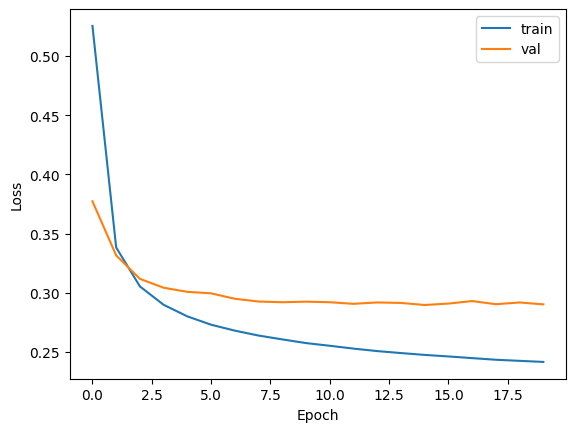

In [328]:
def plot_history_loss(history):
    hist = pd.DataFrame(history.history)
    hist['epoch'] = history.epoch

    plt.figure()
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.plot(hist['epoch'], hist['loss'], label="train")
    plt.plot(hist['epoch'], hist['val_loss'], label="val")
    plt.legend()
    plt.show()

plot_history_loss(history)


Plot historical training and validation accuracy

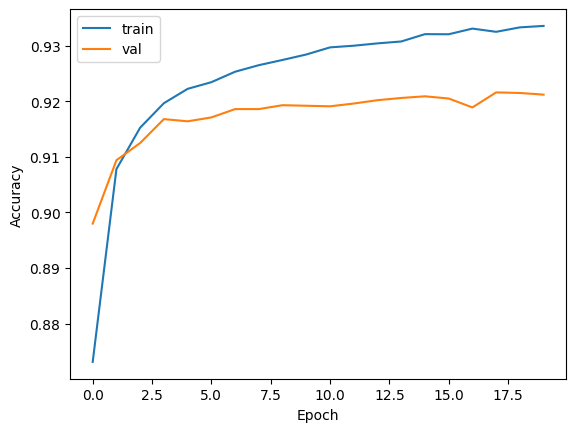

In [39]:
def plot_history(history):
    hist = pd.DataFrame(history.history)
    hist['epoch'] = history.epoch

    plt.figure()
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.plot(hist['epoch'], hist['accuracy'], label="train")
    plt.plot(hist['epoch'], hist['val_accuracy'], label="val")
    plt.legend()
    plt.show()

plot_history(history)


### Evaluate the model

In [329]:
_, acc = evaluate_model(model, X_test, y_test_idx)
print("Testing set accuracy: {:.2f}%".format(acc*100))


Testing set accuracy: 92.86%


### Build the model **2**: Two-layer fully-connected NN

In [312]:
# Please fill in the blanks
# Two-layer fully-connected NN

class TwoLayerNN(nn.Module):
    def __init__(self):
        super().__init__()

        # 512 gave 98% 
        # 88 gave 97%
        # 128 gave 97%
        # 256 gave 98%

        self.nodes = 128
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, self.nodes),
            nn.ReLU(),
            nn.Linear(self.nodes, 10)
        )

    def forward(self, x):
        logits = self.linear_relu_stack(x)
        return logits


model = TwoLayerNN().to(device)


###same as model 1
optimizer = torch.optim.RMSprop(model.parameters(), lr=0.001)
criterion = F.cross_entropy
metric_fn = accuracy

In [276]:
# made fix from model.summary(model)
model_summary(model)

TwoLayerNN(
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=30, bias=True)
    (1): ReLU()
    (2): Linear(in_features=30, out_features=10, bias=True)
  )
)

Total params: 23,860
Trainable params: 23,860


### Train the model

In [313]:
EPOCHS = 20

history = train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    epochs=EPOCHS,
    metric_fn=metric_fn,
)


Epoch 01/20 - loss: 0.3426 - acc: 0.9046 - val_loss: 0.2379 - val_acc: 0.9342
Epoch 02/20 - loss: 0.1868 - acc: 0.9464 - val_loss: 0.1812 - val_acc: 0.9476
Epoch 03/20 - loss: 0.1375 - acc: 0.9601 - val_loss: 0.1780 - val_acc: 0.9485
Epoch 04/20 - loss: 0.1076 - acc: 0.9691 - val_loss: 0.1316 - val_acc: 0.9633
Epoch 05/20 - loss: 0.0865 - acc: 0.9754 - val_loss: 0.1180 - val_acc: 0.9657
Epoch 06/20 - loss: 0.0709 - acc: 0.9791 - val_loss: 0.1076 - val_acc: 0.9682
Epoch 07/20 - loss: 0.0595 - acc: 0.9829 - val_loss: 0.1016 - val_acc: 0.9692
Epoch 08/20 - loss: 0.0506 - acc: 0.9856 - val_loss: 0.0961 - val_acc: 0.9695
Epoch 09/20 - loss: 0.0423 - acc: 0.9883 - val_loss: 0.0963 - val_acc: 0.9704
Epoch 10/20 - loss: 0.0355 - acc: 0.9908 - val_loss: 0.0933 - val_acc: 0.9728
Epoch 11/20 - loss: 0.0306 - acc: 0.9923 - val_loss: 0.0938 - val_acc: 0.9722
Epoch 12/20 - loss: 0.0257 - acc: 0.9933 - val_loss: 0.0929 - val_acc: 0.9743
Epoch 13/20 - loss: 0.0220 - acc: 0.9944 - val_loss: 0.0955 - va

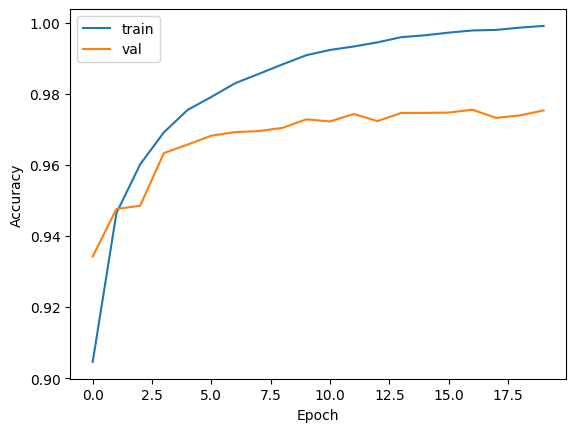

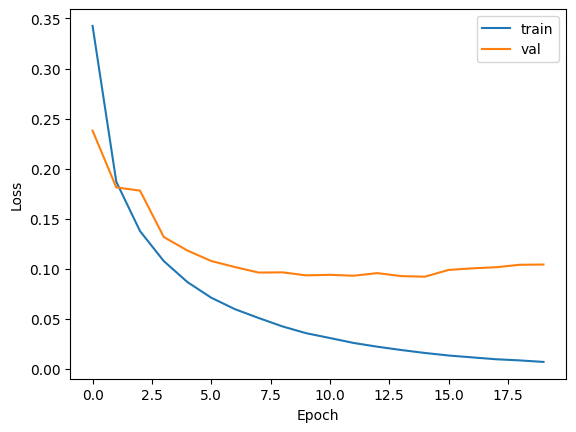

In [314]:
plot_history(history)
plot_history_loss(history) # Remove

###Evaluate the model

In [315]:
_, acc = evaluate_model(model, X_test, y_test_idx)
print("Testing set accuracy: {:.2f}%".format(acc*100))


Testing set accuracy: 97.67%


### Make predictions for testing data

In [247]:
###Make precitions for X_test
y_pred = (predict_proba(model, X_test)).argmax(axis=1)
y_pred[:5]

array([7, 2, 1, 0, 4])

### Visualize the predictions.
#### Does your algorithm work as expected?

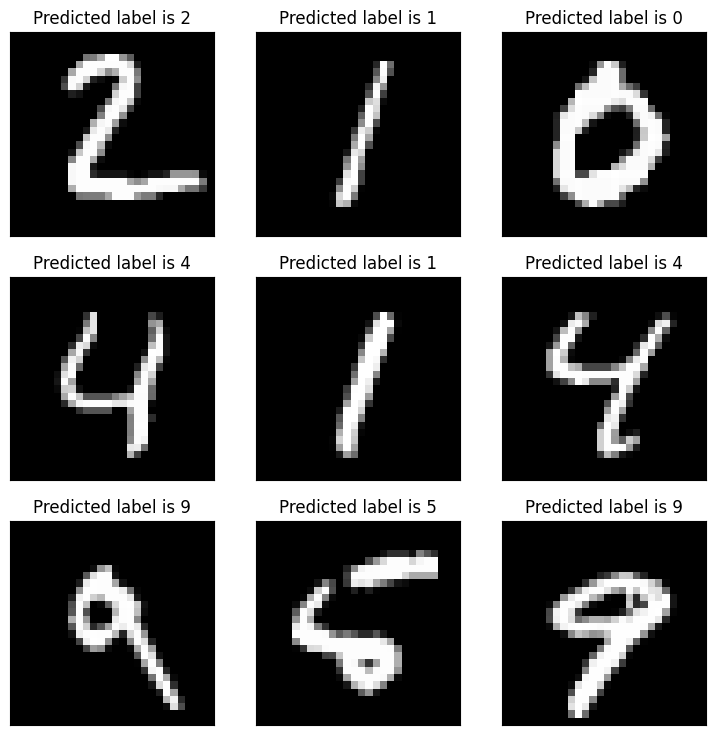

In [170]:
fig = plt.figure(figsize=(9, 9))
col = 3
row = 3
for i in range(1, col*row +1):
    pred = y_pred[i]
    img = X_test_pre[i,:]
    fig.add_subplot(row, col, i)
    plt.title('Predicted label is {}'.format(pred))
    plt.xticks([])
    plt.yticks([])
    plt.imshow(img, cmap='gray')
plt.show()

# comparing the label with the images, the model seems to be working

### Build the model **3**: Model 2 with early stopping

In [316]:
# Build a new model (same architecture as above)
model = TwoLayerNN().to(device)
optimizer = torch.optim.RMSprop(model.parameters(), lr=0.001)
criterion = F.cross_entropy
metric_fn = accuracy

### Train the model with early stopping

Early stopping can be implemented by creating a custom class to monitor the validation loss or another metric and halt the training process if no improvement is observed for a specified number of epochs (patience). Libraries like PyTorch Lightning offer a built-in EarlyStopping callback that automates this process. In our code, we have already set up a patience parameter to control early stopping.

Patience: Number of epochs with no improvement after which training will be stopped. Defaults to 0.

In [317]:
EPOCHS = 20

# Early stopping: stop if val_loss doesn't improve for 2 epochs
# Fill in the following blanks

history = train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    epochs=EPOCHS,
    metric_fn=metric_fn,
    # patience = 2,
    # correcting parameter
    early_stop_patience = 2
)


Epoch 01/20 - loss: 0.3394 - acc: 0.9031 - val_loss: 0.2472 - val_acc: 0.9305
Epoch 02/20 - loss: 0.1864 - acc: 0.9465 - val_loss: 0.1839 - val_acc: 0.9461
Epoch 03/20 - loss: 0.1379 - acc: 0.9601 - val_loss: 0.1481 - val_acc: 0.9558
Epoch 04/20 - loss: 0.1068 - acc: 0.9687 - val_loss: 0.1261 - val_acc: 0.9624
Epoch 05/20 - loss: 0.0858 - acc: 0.9750 - val_loss: 0.1210 - val_acc: 0.9645
Epoch 06/20 - loss: 0.0704 - acc: 0.9801 - val_loss: 0.1083 - val_acc: 0.9695
Epoch 07/20 - loss: 0.0594 - acc: 0.9823 - val_loss: 0.1075 - val_acc: 0.9688
Epoch 08/20 - loss: 0.0503 - acc: 0.9855 - val_loss: 0.1030 - val_acc: 0.9698
Epoch 09/20 - loss: 0.0429 - acc: 0.9875 - val_loss: 0.1040 - val_acc: 0.9700
Epoch 10/20 - loss: 0.0365 - acc: 0.9902 - val_loss: 0.0964 - val_acc: 0.9725
Epoch 11/20 - loss: 0.0315 - acc: 0.9911 - val_loss: 0.0938 - val_acc: 0.9747
Epoch 12/20 - loss: 0.0269 - acc: 0.9927 - val_loss: 0.0918 - val_acc: 0.9741
Epoch 13/20 - loss: 0.0225 - acc: 0.9944 - val_loss: 0.1007 - va

### Evaluate the model

In [318]:
_, acc = evaluate_model(model, X_test, y_test_idx)
print("Testing set accuracy: {:.2f}%".format(acc*100))


Testing set accuracy: 97.63%


### What are your findings?
Implementing early stopping allowed for a shorter training time while achieving the same level of accuracy

# Building Model 4: Binary Classification

How to write the code for a binary classification problem?

## Data Preprocessing

Consider predicting whether a handwritten digit is '8' or not.

In [319]:
y_train_8=y_train[:,8]
y_test_8=y_test[:,8]
y_val_8=y_val[:,8]

Generated labels are binary: 0 if the digit is not '8', 1 if the digit is '8'.

In [320]:
y_train_8

array([0., 0., 0., ..., 0., 0., 0.], shape=(50000,), dtype=float32)

Build a binary classification model. Difference

1. Output dimension for the final layer is 1
2. Activation function for the final layer is 'sigmoid'
3. Loss function is 'binary_crossentropy'



## Build the model

In [321]:
# Build a binary classification model
# Differences from multi-class:
# 1) Output dimension is 1 (logit)
# 2) Use BCEWithLogitsLoss (so NO sigmoid in the model)

class BinaryNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer = nn.Linear(in_features=784, out_features=1)

    def forward(self, x):
        return self.layer(x).squeeze(1) # Need to squeeze so there is no mismatch error with targets



model = BinaryNN().to(device)
optimizer = torch.optim.RMSprop(model.parameters(), lr=0.001) # same optimizer
criterion = nn.BCEWithLogitsLoss()


In [322]:
model_summary(model)

BinaryNN(
  (layer): Linear(in_features=784, out_features=1, bias=True)
)

Total params: 785
Trainable params: 785


## Train the model

Train the model on the binary labels.

In [323]:
def make_binary_loaders(X_train, y_train_bin, X_val, y_val_bin, batch_size=128):
    Xtr = torch.from_numpy(X_train).float()
    ytr = torch.from_numpy(y_train_bin).float()
    Xva = torch.from_numpy(X_val).float()
    yva = torch.from_numpy(y_val_bin).float()

    train_loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(TensorDataset(Xva, yva), batch_size=batch_size, shuffle=False)
    return train_loader, val_loader


def train_model_binary(model, train_loader, val_loader, optimizer, criterion, epochs, early_stop_patience=None):
    history = History()
    best_val = float('inf')
    best_state = None
    patience_left = early_stop_patience

    for ep in range(epochs):
        model.train()
        train_loss_sum, train_correct, train_n = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            bs = xb.size(0)
            train_loss_sum += loss.item() * bs
            preds = (torch.sigmoid(logits) > 0.5).float()
            train_correct += (preds == yb).sum().item()
            train_n += bs

        train_loss = train_loss_sum / train_n
        train_acc = train_correct / train_n

        model.eval()
        val_loss_sum, val_correct, val_n = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)

                bs = xb.size(0)
                val_loss_sum += loss.item() * bs
                preds = (torch.sigmoid(logits) > 0.5).float()
                val_correct += (preds == yb).sum().item()
                val_n += bs

        val_loss = val_loss_sum / val_n
        val_acc = val_correct / val_n

        history.epoch.append(ep)
        history.history['loss'].append(train_loss)
        history.history['val_loss'].append(val_loss)
        history.history['accuracy'].append(train_acc)
        history.history['val_accuracy'].append(val_acc)

        print(f"Epoch {ep+1:02d}/{epochs} - loss: {train_loss:.4f} - acc: {train_acc:.4f} - val_loss: {val_loss:.4f} - val_acc: {val_acc:.4f}")

        if early_stop_patience is not None:
            if val_loss < best_val - 1e-8:
                best_val = val_loss
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                patience_left = early_stop_patience
            else:
                patience_left -= 1
                if patience_left < 0:
                    print('Early stopping triggered.')
                    break

    if best_state is not None:
        model.load_state_dict(best_state)

    return history


def evaluate_model_binary(model, X, y_bin, batch_size=256):
    model.eval()
    Xte = torch.from_numpy(X).float()
    yte = torch.from_numpy(y_bin).float()
    loader = DataLoader(TensorDataset(Xte, yte), batch_size=batch_size, shuffle=False)

    criterion = nn.BCEWithLogitsLoss()
    loss_sum, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            bs = xb.size(0)
            loss_sum += loss.item() * bs
            preds = (torch.sigmoid(logits) > 0.5).float()
            correct += (preds == yb).sum().item()
            n += bs

    return loss_sum / n, correct / n


EPOCHS = 10

train_loader_bin, val_loader_bin = make_binary_loaders(X_train, y_train_8, X_val, y_val_8, batch_size=128)

history = train_model_binary(
    model,
    train_loader_bin,
    val_loader_bin,
    optimizer,
    criterion,
    epochs=EPOCHS,
)


Epoch 01/10 - loss: 0.2222 - acc: 0.9261 - val_loss: 0.1769 - val_acc: 0.9454
Epoch 02/10 - loss: 0.1702 - acc: 0.9443 - val_loss: 0.1592 - val_acc: 0.9496
Epoch 03/10 - loss: 0.1582 - acc: 0.9488 - val_loss: 0.1510 - val_acc: 0.9509
Epoch 04/10 - loss: 0.1515 - acc: 0.9504 - val_loss: 0.1525 - val_acc: 0.9503
Epoch 05/10 - loss: 0.1468 - acc: 0.9526 - val_loss: 0.1428 - val_acc: 0.9532
Epoch 06/10 - loss: 0.1432 - acc: 0.9531 - val_loss: 0.1404 - val_acc: 0.9536
Epoch 07/10 - loss: 0.1403 - acc: 0.9545 - val_loss: 0.1375 - val_acc: 0.9541
Epoch 08/10 - loss: 0.1378 - acc: 0.9553 - val_loss: 0.1354 - val_acc: 0.9541
Epoch 09/10 - loss: 0.1357 - acc: 0.9562 - val_loss: 0.1341 - val_acc: 0.9551
Epoch 10/10 - loss: 0.1336 - acc: 0.9568 - val_loss: 0.1321 - val_acc: 0.9565


## Evaluate the model

The binary classification task is easier than the 10-class one. It is expected we see a better performance.

In [324]:
_, acc = evaluate_model_binary(model, X_test, y_test_8)
print("Testing set accuracy: {:.2f}%".format(acc*100))


Testing set accuracy: 95.61%


### Summarize your findings

We see an $\approx 3%$ increase in the testing accuracy for the binary classification compared to multinomial, mostly because of a simpler decision boundry